In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import joblib
# import umap
from statistics import mean
from sklearn.metrics.pairwise import cosine_similarity

# locations of previously generated simulation data
DATADIR = Path('~/ECM_mod_output').expanduser()
DATADIR.mkdir(exist_ok=True)   # create the directory if it doesn't exist  

# Where to save large simulation output files
SAVE_DIR = DATADIR / 'dist_runs'
SAVE_DIR.mkdir(exist_ok=True)   # create the directory if it doesn't exist

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

sys_type = sys.platform

### UMAP embedding is platform-specific
Define path to embedding (reducer) based on system platform

In [2]:
r_name = 'reducer_20240502_0.1_0.1_4_0.5.sav'

if sys_type == 'darwin':
    r_path_date = '20240502'
    r_dbpath = 'https://www.dropbox.com/scl/fi/ovk8v5fc9rvsbm43zww8h/reducer_20240502_0.1_0.1_4_0.5.sav?rlkey=jb9om518rtjth0q9bs6mdjj79&dl=1'
if sys_type == 'win32': 
    r_path_date = '03_20'
    r_dbpath = 'https://www.dropbox.com/scl/fi/jlfya4m3bhp9akr3hzco2/reducer_03_20_0.1_0.1_4_0.5.sav?rlkey=3z8ozy95khsjdqplkg8ce11md&dl=1'
if sys_type == 'linux': 
    r_path_date = '20240606'
    r_dbpath = "https://www.dropbox.com/scl/fi/79lp5174wny1ngiy4w1h7/reducer_20240606_0.1_0.1_4_0.5.sav?rlkey=3p1xkbzkdmwy9ivmn5r64xtlh&dl=1"

r_path = Path(DATADIR,'UMAP',r_name.replace('20240502',r_path_date))

# Set the environment variables; needed for downloading data files from Dropbox
%env R_PATH = {r_path}
%env R_DBPATH = {r_dbpath}

env: R_PATH=/Users/darren/ECM_mod_output/UMAP/reducer_20240502_0.1_0.1_4_0.5.sav
env: R_DBPATH=https://www.dropbox.com/scl/fi/ovk8v5fc9rvsbm43zww8h/reducer_20240502_0.1_0.1_4_0.5.sav?rlkey=jb9om518rtjth0q9bs6mdjj79&dl=1


### Define function to load and normalize simulation data
Scaling the values of each molecular species to the min/max of experimental conditions (range = 0-1)


In [3]:
def calc_minmax(filenames, filenames_ode):
    # values to be replaced
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this now
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames_ode:
        tmp_max=[]
        tmp_min=[]
        prot_tmp_ode = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp_ode[col].max() for col in prot_tmp_ode]
        tmp_min = [prot_tmp_ode[col].min() for col in prot_tmp_ode]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]  
        
    return max_prots, min_prots


def load_norm_data(filenames, filenames_ode, max_prots, min_prots, time_all, init_dt, dt, window, time_step, plot_phase):
     
    if plot_phase:
        plot_phase(filenames_sp, filenames_sp_ode)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_{num}.png"), bbox_inches='tight')
        plot_phase_norm(filenames_sp, filenames_sp_ode, max_prots, min_prots)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_norm_{num}.png"), bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp

### Load previously generated simulation data
example file name: `stoch_sim_dmso_stiff000_orig.csv`  


In [4]:
stoch_sim_files = list(DATADIR.glob('stoch_sim*_orig.csv'))
stoch_sim_files.sort()
stoch_sim_files

[PosixPath('/Users/darren/ECM_mod_output/stoch_sim_DMSO_stiff_000_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_DMSO_stiff_029_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_DMSO_stiff_049_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_DMSO_stiff_074_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_DMSO_stiff_099_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_ERL_stiff_000_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_ERL_stiff_029_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_ERL_stiff_049_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_ERL_stiff_074_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/stoch_sim_ERL_stiff_099_orig.csv')]

In [5]:
ode_sim_files = list(DATADIR.glob('ODE_sim*_orig.csv'))
ode_sim_files.sort()
ode_sim_files

[PosixPath('/Users/darren/ECM_mod_output/ODE_sim_DMSO_stiff_000_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/ODE_sim_DMSO_stiff_029_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/ODE_sim_DMSO_stiff_049_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/ODE_sim_DMSO_stiff_074_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/ODE_sim_DMSO_stiff_099_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/ODE_sim_ERL_stiff_000_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/ODE_sim_ERL_stiff_029_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/ODE_sim_ERL_stiff_049_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/ODE_sim_ERL_stiff_074_orig.csv'),
 PosixPath('/Users/darren/ECM_mod_output/ODE_sim_ERL_stiff_099_orig.csv')]

In [6]:
max_prots, min_prots = calc_minmax(stoch_sim_files, ode_sim_files)

# define the time range of the simulation to use
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]

# plot_phase not needed
plot_phase = False

### Define UMAP parameters
These should not change

In [7]:
# Important params to set the window size and step time distance
init_dt = 0.1                 # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.01

# set the random state for reproducibility; set to None to get different results each time
RANDOM_STATE = 42


### Load and normalize all data

In [8]:
[all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(stoch_sim_files, ode_sim_files, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


### Load previously generated UMAP embedding reducer


In [9]:
if not r_path.exists():
    !wget -O $R_PATH $R_DBPATH
reducer = joblib.load(r_path)

/Users/darren/miniforge3/envs/ECM_model/lib/python3.10/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/Users/darren/miniforge3/envs/ECM_model/lib/python3.10/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/Users/darren/miniforge3/envs/ECM_model/lib/python3.10/site-

### Embed data in UMAP space
Use abbreviated time window (only first 2000 time steps) for ODE simulations

In [10]:
embedding_all_prot = reducer.transform(all_prot_tmp)

win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_tmp_ode)/len(stoch_sim_files)
sp = 1
for n in range(len(stoch_sim_files)):
    tmp = all_prot_tmp_ode[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

### Define track lengths and colors


In [11]:
trk_len = int(len(embedding_all_prot)/len(stoch_sim_files))
trk_len_ode = int(len(embedding_all_prot_ode)/len(stoch_sim_files))

colors_blue = plt.cm.Blues(np.linspace(0,1,5))
colors_red = plt.cm.Reds(np.linspace(0,1,5))
colors_accent = plt.cm.jet(np.linspace(0,1,5))

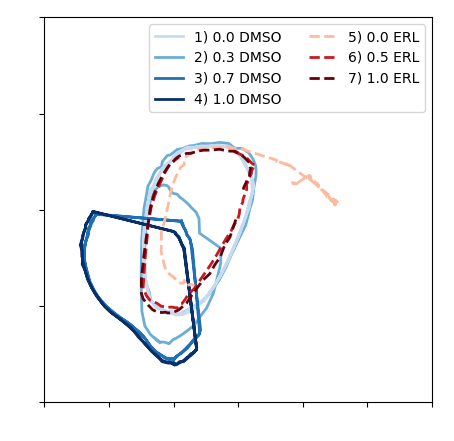

In [12]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)

n=0
n1=1

lw = 2


plt.plot(embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,0], 
         embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[2], label='2) 0.3 DMSO')
plt.plot(embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+150,0], 
         embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+150,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[1], label='1) 0.0 DMSO')
plt.plot(embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+100,0], 
         embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[3], label='3) 0.7 DMSO')
plt.plot(embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+100,0], 
         embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[4], label='4) 1.0 DMSO')

plt.plot(embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+150,0], 
         embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+150,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[1], label='5) 0.0 ERL')
plt.plot(embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+60,0], 
         embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+60,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[3], label='6) 0.5 ERL')
plt.plot(embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,0], 
         embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[4], label='7) 1.0 ERL')

plt.xlim(-5,20)
plt.ylim(0, 15)
plt.xticks(np.arange(-10, 21, step=5))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

handles, labels = plt.gca().get_legend_handles_labels()
order = [1,0,2,3,4,5,6]
plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order], loc="upper right", ncol=2)



In [15]:
def restructProt(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF.iloc[:,int((win_len*11+win_len/2)-1)], prominence = 30/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF.iloc[:,int((win_len*17+win_len/2)-1)], prominence = 30/200, distance = 10)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    num = 1
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp_g1s = [int(ordered[1])]*len(tmp_time)
            tmp_mit = [int(ordered[2])]*len(tmp_time)
            tmp_g1s2 = [int(ordered[3])]*len(tmp_time)
            tmp_mit2 = [int(ordered[4])]*len(tmp_time)
            
            tmp_time.insert(0, 'mit2', tmp_mit2)
            tmp_time.insert(0, 'G1-S_2', tmp_g1s2)
            tmp_time.insert(0, 'mit', tmp_mit)
            tmp_time.insert(0, 'G1-S', tmp_g1s)
            tmp_time.insert(0, 'G1_len', tmp)
            tmp_time.insert(0, 'div', [num]*len(tmp_time))
            num += 1
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [16]:
trk_len = int(len(all_prot_tmp)/len(stoch_sim_files))
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']

dmso_000_prot_df = pd.DataFrame(all_prot_tmp[0*trk_len:1*trk_len,:])
dmso_000_time_df = pd.DataFrame(all_time_tmp[0*trk_len:1*trk_len,:])
dmso_000_emb_df = pd.DataFrame(embedding_all_prot[0*trk_len:1*trk_len,:])

dmso_030_prot_df = pd.DataFrame(all_prot_tmp[1*trk_len:2*trk_len,:])
dmso_030_time_df = pd.DataFrame(all_time_tmp[1*trk_len:2*trk_len,:])
dmso_030_emb_df = pd.DataFrame(embedding_all_prot[1*trk_len:2*trk_len,:])

dmso_050_prot_df = pd.DataFrame(all_prot_tmp[2*trk_len:3*trk_len,:])
dmso_050_time_df = pd.DataFrame(all_time_tmp[2*trk_len:3*trk_len,:])
dmso_050_emb_df = pd.DataFrame(embedding_all_prot[2*trk_len:3*trk_len,:])

dmso_070_prot_df = pd.DataFrame(all_prot_tmp[3*trk_len:4*trk_len,:])
dmso_070_time_df = pd.DataFrame(all_time_tmp[3*trk_len:4*trk_len,:])
dmso_070_emb_df = pd.DataFrame(embedding_all_prot[3*trk_len:4*trk_len,:])

dmso_099_prot_df = pd.DataFrame(all_prot_tmp[4*trk_len:5*trk_len,:])
dmso_099_time_df = pd.DataFrame(all_time_tmp[4*trk_len:5*trk_len,:])
dmso_099_emb_df = pd.DataFrame(embedding_all_prot[4*trk_len:5*trk_len,:])

erl_000_prot_df = pd.DataFrame(all_prot_tmp[5*trk_len:6*trk_len,:])
erl_000_time_df = pd.DataFrame(all_time_tmp[5*trk_len:6*trk_len,:])
erl_000_emb_df = pd.DataFrame(embedding_all_prot[5*trk_len:6*trk_len,:])

erl_050_prot_df = pd.DataFrame(all_prot_tmp[6*trk_len:7*trk_len,:])
erl_050_time_df = pd.DataFrame(all_time_tmp[5*trk_len:6*trk_len,:])
erl_050_emb_df = pd.DataFrame(embedding_all_prot[6*trk_len:7*trk_len,:])

erl_099_prot_df = pd.DataFrame(all_prot_tmp[7*trk_len:8*trk_len,:])
erl_099_time_df = pd.DataFrame(all_time_tmp[5*trk_len:6*trk_len,:])
erl_099_emb_df = pd.DataFrame(embedding_all_prot[7*trk_len:8*trk_len,:])


In [18]:
# erl_099_cycdi_prot_df = pd.DataFrame(all_prot_tmp_cycdi[5*trk_len:6*trk_len,:])
# erl_099_cycdi_time_df = pd.DataFrame(all_prot_tmp_cycdi[5*trk_len:6*trk_len,:])
# erl_099_cycdi_emb_df = pd.DataFrame(embedding_all_prot_cycdi[5*trk_len:6*trk_len,:])

In [ ]:
erl_050_prot_df.shape

(39993, 720)

In [21]:
from scipy.signal import find_peaks

In [22]:
mit_win_dmso_050, time_win_dmso_050, umap_win_dmso_050 = restructProt(dmso_050_prot_df, dmso_050_emb_df, dmso_050_time_df)
mit_win_dmso_000, time_win_dmso_000, umap_win_dmso_000 = restructProt(dmso_000_prot_df, dmso_000_emb_df, dmso_000_time_df)
mit_win_dmso_030, time_win_dmso_030, umap_win_dmso_030 = restructProt(dmso_030_prot_df, dmso_030_emb_df, dmso_030_time_df)
mit_win_dmso_070, time_win_dmso_070, umap_win_dmso_070 = restructProt(dmso_070_prot_df, dmso_070_emb_df, dmso_070_time_df)
mit_win_dmso_099, time_win_dmso_099, umap_win_dmso_099 = restructProt(dmso_099_prot_df, dmso_099_emb_df, dmso_099_time_df)

In [23]:
mit_win_erl_000, time_win_erl_000, umap_win_erl_000 = restructProt(erl_000_prot_df, erl_000_emb_df, erl_000_time_df)
mit_win_erl_050, time_win_erl_050, umap_win_erl_050 = restructProt(erl_050_prot_df, erl_050_emb_df, erl_050_time_df)
mit_win_erl_099, time_win_erl_099, umap_win_erl_099 = restructProt(erl_099_prot_df, erl_099_emb_df, erl_099_time_df)

In [24]:
# mit_win_erl_cycdi_099, time_win_erl_cycdi_099, umap_win_erl_cycdi_099 = restructProt(erl_099_cycdi_prot_df, erl_099_cycdi_emb_df, erl_099_cycdi_time_df)


NameError: name 'erl_099_cycdi_prot_df' is not defined

In [19]:
size = (4,4)
xmin = -10
xmax = 20
ymin = 0
ymax = 20
wid = 1
trk_len_ode = int(len(embedding_all_prot_ode)/len(stoch_sim_files))
import scipy as sp

In [25]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
xmin, xmax = -10, 20
ymin, ymax = 0, 20

x = np.array(umap_win_erl_cycdi_099[0])
y = np.array(umap_win_erl_cycdi_099[1])
H, xedges, yedges = np.histogram2d(x, y, bins=100, range= [[xmin,xmax], [ymin,ymax]], density=True)
# Apply gaussian filter
sigma = [3, 3]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0



ax = fig.gca()

tmp = embedding_all_prot_ode_conds[5*trk_len_ode:6*trk_len_ode,:]
im = plt.imshow((np.rot90(H)), extent=[xmin, xmax, ymin, ymax], 
                interpolation='bilinear', cmap='inferno', aspect='auto')
im.set_clim(0, 0.03)
plt.plot(tmp[500:,0], tmp[500:,1],
         lw=0.5, alpha=1)

plt.xlim(-10,20)
plt.ylim(0, 20)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))


plt.xticks(color='w')
plt.yticks(color='w')

cbar_ax = fig.add_axes([0.74, 0.63, 0.05, 0.2])
cb = fig.colorbar(im, cax=cbar_ax)
cb.ax.tick_params(labelsize=9)
cb.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='white')

plt.savefig(str(SAVE_DIR)+"\\ERL_100_cycdi_heatmap.svg", format="svg")


NameError: name 'umap_win_erl_cycdi_099' is not defined

<Figure size 500x500 with 0 Axes>

In [ ]:
sys.path.insert(0, "./../../../Vector_Similarity/python/TS_SS")
from Vector_Similarity import *

2.23606797749979
0.9999999999999998
0.0004639582566999478


In [ ]:
w_len = int(len(all_prot_tmp_ode)/len(filenames_sp))


In [ ]:
n=5
n1=6

# prot_vec=all_prot_tmp_conds[n*w_len:n1*w_len,:]
prot_vec=all_prot_tmp_cycdi[n*w_len:n1*w_len,:]
offset=1
v_len=1

In [ ]:
prot_inds = np.arange(n*w_len,n1*w_len,offset)

In [ ]:
prot_inds

array([199965, 199966, 199967, ..., 239955, 239956, 239957])

In [ ]:
def calc_sim(prot_vec, offset, v_len, prot_inds):
    #prot_inds = np.arange(0,len(prot_vec),offset)
    euc_vals = []
    cos_vals = []
    TS_SS_vals = []
    
    for val in range(len(prot_inds)-2):
        vec1=all_prot_tmp_conds[prot_inds[val]+v_len,:] - all_prot_tmp_conds[prot_inds[val],:]
        vec2=all_prot_tmp_conds[prot_inds[val+1]+v_len,:] - all_prot_tmp_conds[prot_inds[val+1],:]
        euc_vals.append(Euclidean(vec1,vec2))
        cos_vals.append(Cosine(vec1,vec2))
        TS_SS_vals.append(TS_SS(vec1,vec2))
        
    return euc_vals, cos_vals, TS_SS_vals

In [ ]:
def calc_sim_drug(prot_vec, offset, v_len, prot_inds):
    #prot_inds = np.arange(0,len(prot_vec),offset)
    euc_vals = []
    cos_vals = []
    TS_SS_vals = []
    
    for val in range(len(prot_inds)-2):
        vec1=all_prot_tmp_cycdi[prot_inds[val]+v_len,:] - all_prot_tmp_cycdi[prot_inds[val],:]
        vec2=all_prot_tmp_cycdi[prot_inds[val+1]+v_len,:] - all_prot_tmp_cycdi[prot_inds[val+1],:]
        euc_vals.append(Euclidean(vec1,vec2))
        cos_vals.append(Cosine(vec1,vec2))
        TS_SS_vals.append(TS_SS(vec1,vec2))
        
    return euc_vals, cos_vals, TS_SS_vals

In [ ]:
euc_vals, cos_vals, TS_SS_vals = calc_sim_drug(prot_vec, offset, v_len, prot_inds)

In [ ]:
euc_vals, cos_vals, TS_SS_vals = calc_sim(prot_vec, offset, v_len, prot_inds)

In [ ]:
log_euc_vals=[math.log(val) for val in euc_vals]
log_TS_SS_vals=[math.log(val) for val in TS_SS_vals]

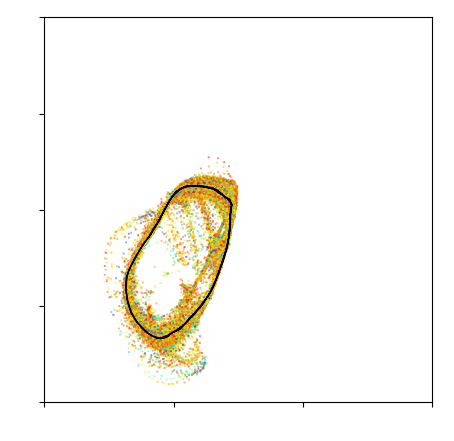

In [ ]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)

scatter1 = plt.scatter(embedding_all_prot_conds[prot_inds[:-2],0], embedding_all_prot_conds[prot_inds[:-2],1],
           s=0.2, alpha=0.6, vmin=-0.5, vmax=1, c=cos_vals, cmap='jet_r')

tmp = embedding_all_prot_ode_conds[5*trk_len_ode:6*trk_len_ode,:]
plt.plot(tmp[500:650,0], tmp[500:650,1],
         lw=1, alpha=1, color='black')

plt.xlim(-10,20)
plt.ylim(0, 20)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

# cbar_ax = fig.add_axes([0.78, 0.65, 0.03, 0.2])
# cb = fig.colorbar(scatter1, cax=cbar_ax)
# cb.ax.tick_params(labelsize=9)

# cb.ax.yaxis.set_tick_params(color='white')
# plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='white')

# plt.savefig(str(SAVE_DIR)+"\\ERL_100_veccos.svg", format="svg")


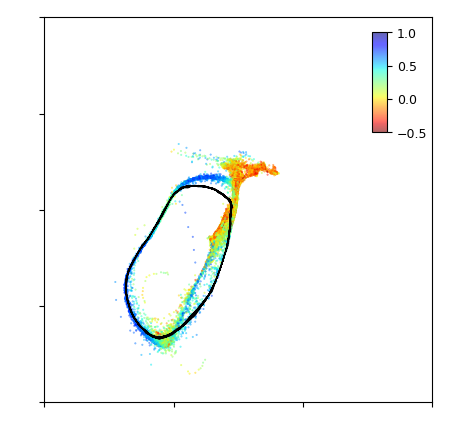

In [ ]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)

scatter1 = plt.scatter(embedding_all_prot_cycdi[prot_inds[:-2],0], embedding_all_prot_cycdi[prot_inds[:-2],1],
           s=0.2, alpha=0.6, vmin=-0.5, vmax=1, c=cos_vals, cmap='jet_r')

tmp = embedding_all_prot_ode_conds[5*trk_len_ode:6*trk_len_ode,:]
plt.plot(tmp[500:,0], tmp[500:,1],
         lw=0.5, alpha=1, color='black')

plt.xlim(-10,20)
plt.ylim(0, 20)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))


plt.xticks(color='w')
plt.yticks(color='w')

cbar_ax = fig.add_axes([0.78, 0.65, 0.03, 0.2])
cb = fig.colorbar(scatter1, cax=cbar_ax)
cb.ax.tick_params(labelsize=9)

# cb.ax.yaxis.set_tick_params(color='white')
# plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='white')

# plt.savefig(str(SAVE_DIR)+"\\ERL_100_cycdi_veccos.svg", format="svg")